# 第 19 章：波动率微笑与曲面

本章的微笑、密度与曲面，都从定义搭起来，并复现本章印出的数字。**只用 NumPy**（图用
matplotlib）。Breeden–Litzenberger 密度、方差期权序列、翼部斜率上限、粘性 delta 修正
与曲面插值都逐条写出，而不是从库里调用，于是正文里的公式与代码一一对应。

| 节 | 搭什么 | 正文 |
|---|---|---|
| 1 | 布莱克–斯科尔斯–默顿公式、vega、隐含波动率、`show` 辅助函数 | — |
| 2 | 波动率偏斜、偏斜的斜率与标准化价值状态 | 图 19.1，表 19.1 |
| 3 | 微笑隐含的密度及其尾部 | 式 (19.1)，例 19.1，图 19.2 |
| 4 | 由六个报价得到一个分布 | 例 19.2 |
| 5 | 一年期偏斜上的方差期权序列 | 式 (19.2)，第 19.3 节 |
| 6 | 翼部最多能陡升多快 | 例 19.3 |
| 7 | 预定事件的方差 | 第 19.6 节 |
| 8 | 隐含相关性 | 式 (19.3)，例 19.4 |
| 9 | 粘性执行价、粘性 delta 与 delta 修正 | 式 (19.4)，例 19.5，图 19.4 |
| 10 | 标普 500 曲面，以及为不交易的期权定价 | 表 19.3，例 19.6 |

每个算出的数字都与本章印出的数字并列显示；在本章的舍入精度内一致时标为 `ok`。
本章没有印出的数字则只打印计算值。第 19.13 节的境内内容（例 19.7，融券费率造成的
偏斜）只用到一次平价关系的移动与一个 vega，这里不重复。

## 1. 公式与核对用的辅助函数

`bs` 是带收益率 $q$ 的布莱克–斯科尔斯–默顿价格，`vega` 是它对波动率的敏感度，
`implied_vol` 用二分法反解价格；价格随波动率单调上升，所以二分法可行。`show` 把
算出的值与本章印出的值并列打印。

In [1]:
import numpy as np
from math import log, sqrt, exp, erf, pi


def N(x):
    return 0.5 * (1.0 + erf(x / sqrt(2.0)))


def phi(x):
    return exp(-0.5 * x * x) / sqrt(2.0 * pi)


def show(label, got, printed, tol=None):
    # tol defaults to half a unit in the last printed digit
    if tol is None and isinstance(printed, int):
        tol = 0.5
    elif tol is None:
        s = repr(float(printed)).split(".")
        tol = 0.5 * 10 ** -len(s[1]) + 1e-12
    flag = "ok" if abs(got - printed) <= tol else "DIFFERS"
    print("%-56s %12.6g   book %10.6g   %s" % (label, got, printed, flag))


def note(label, got):
    print("%-56s %12.6g" % (label, got))


def d12(S, K, T, r, sig, q=0.0):
    d1 = (log(S / K) + (r - q + 0.5 * sig * sig) * T) / (sig * sqrt(T))
    return d1, d1 - sig * sqrt(T)


def bs(S, K, T, r, sig, q=0.0, call=True):
    d1, d2 = d12(S, K, T, r, sig, q)
    c = S * exp(-q * T) * N(d1) - K * exp(-r * T) * N(d2)
    return c if call else c - S * exp(-q * T) + K * exp(-r * T)


def vega(S, K, T, r, sig, q=0.0):
    d1, _ = d12(S, K, T, r, sig, q)
    return S * exp(-q * T) * phi(d1) * sqrt(T)


def implied_vol(price, S, K, T, r, q=0.0, call=True):
    lo, hi = 1e-4, 3.0
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if bs(S, K, T, r, mid, q, call) > price:
            hi = mid
        else:
            lo = mid
    return 0.5 * (lo + hi)

## 2. 波动率偏斜：图 19.1 与表 19.1

图 19.1 由 $\sigma = 0.20 - 0.055z + 0.018z^2$ 画出，其中 $z = \ln(K/S)/(0.20\sqrt{T})$。
开头几行验证第 19.1 节的第一点：同一执行价的看涨与看跌期权，按同一波动率定价后，
反解出的是同一个波动率，因为平价关系把两者绑在一起。随后，90 与 110 执行价之间
每 10 个执行价点的斜率随期限拉长从 5.7 降到 1.6；而按价值状态的标准差来度量，
三条曲线几乎是同一条。

implied vol from the 90 call (r = 3%)                         0.23397
implied vol from the 90 put                                   0.23397

slope at T = 0.25, points per 10 of strike                    5.69996   book        5.7   ok
slope at T = 1.00, points per 10 of strike                     2.8046   book        2.8   ok
slope at T = 3.00, points per 10 of strike                    1.60816   book        1.6   ok

the 90 strike in standard deviations, T = 0.25                1.05361   book       1.05   ok
the 90 strike in standard deviations, T = 1.00               0.526803   book       0.53   ok
the 90 strike in standard deviations, T = 3.00                0.30415   book        0.3   ok

slope per standard deviation, T = 0.25                        5.68095   book       5.68   ok
slope per standard deviation, T = 1.00                        5.59125   book       5.59   ok
slope per standard deviation, T = 3.00                        5.55856   book       5.56   ok


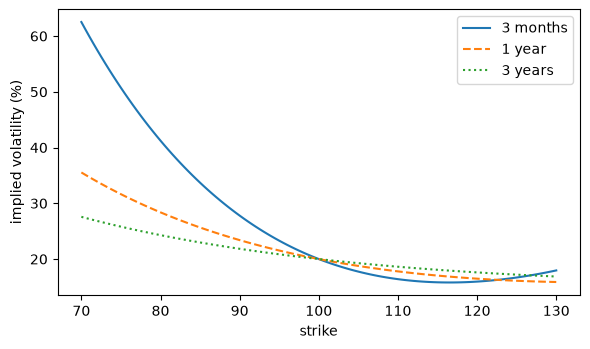

In [2]:
def skew(K, S=100.0, T=1.0):
    # Figure 19.1's smile
    z = log(K / S) / (0.20 * sqrt(T))
    return 0.20 - 0.055 * z + 0.018 * z * z


s90 = skew(90.0)
c90 = bs(100.0, 90.0, 1.0, 0.03, s90)
p90 = bs(100.0, 90.0, 1.0, 0.03, s90, call=False)
note("implied vol from the 90 call (r = 3%)", implied_vol(c90, 100.0, 90.0, 1.0, 0.03))
note("implied vol from the 90 put", implied_vol(p90, 100.0, 90.0, 1.0, 0.03, call=False))
print()
for T, printed in ((0.25, 5.7), (1.0, 2.8), (3.0, 1.6)):
    show("slope at T = %.2f, points per 10 of strike" % T,
         100 * (skew(90.0, T=T) - skew(110.0, T=T)) / 2, printed)
print()
for T, printed in ((0.25, 1.05), (1.0, 0.53), (3.0, 0.30)):
    show("the 90 strike in standard deviations, T = %.2f" % T, -log(0.9) / (0.20 * sqrt(T)), printed)
print()
for T, printed in ((0.25, 5.68), (1.0, 5.59), (3.0, 5.56)):
    lo, hi = round(100 * skew(90.0, T=T), 2), round(100 * skew(110.0, T=T), 2)   # the plotted points
    dz = (log(1.1) - log(0.9)) / (0.20 * sqrt(T))
    show("slope per standard deviation, T = %.2f" % T, (lo - hi) / dz, printed)

try:
    import matplotlib.pyplot as plt
    Ks = np.linspace(70, 130, 121)
    plt.figure(figsize=(6, 3.6))
    for T, style, lab in ((0.25, "-", "3 months"), (1.0, "--", "1 year"), (3.0, ":", "3 years")):
        plt.plot(Ks, [100 * skew(k, T=T) for k in Ks], style, label=lab)
    plt.xlabel("strike")
    plt.ylabel("implied volatility (%)")
    plt.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    pass

## 3. 微笑隐含的密度：式 (19.1) 与例 19.1

Breeden–Litzenberger 结果：$g(K) = e^{rT}\,\partial^2 c/\partial K^2$，沿着微笑求导。
例 19.1 用的是较温和的一年期微笑 $\sigma(K) = 0.20 - 0.15\ln(K/100) + 0.15\ln^2(K/100)$，
取 $r = 0$。每个尾部概率都是一个数字期权，$\Pr(S_T < K) = 1 + dc/dK$，而 $dc/dK$
是沿微笑的全导数：平坦波动率下的数字期权，加上 vega 乘以微笑的斜率。先做对照：
在平坦的 20% 微笑上，同一段代码必须给出对数正态的结果。

In [3]:
S0, T1 = 100.0, 1.0


def smile1(K):
    x = log(K / S0)
    return 0.20 - 0.15 * x + 0.15 * x * x


def dsmile1(K):
    return (-0.15 + 0.30 * log(K / S0)) / K


def prob_below(K, sig, dsig):
    # 1 + dc/dK with r = 0: the digital put along the smile
    s = sig(K)
    _, d2 = d12(S0, K, T1, 0.0, s)
    return N(-d2) + vega(S0, K, T1, 0.0, s) * dsig(K)


def density(K, sig):
    # equation (19.1) by central difference
    h = 1e-4 * K
    c = lambda k: bs(S0, k, T1, 0.0, sig(k))
    return (c(K - h) - 2 * c(K) + c(K + h)) / (h * h)


flat = lambda K: 0.20
dflat = lambda K: 0.0
show("control: flat smile, Pr(S_T < 70) against lognormal",
     prob_below(70, flat, dflat), N((log(0.70) + 0.02) / 0.20), tol=1e-12)
print()
p = {}
for K, left, ps, pl in ((60, True, 3.0, 0.7), (70, True, 6.9, 4.6), (80, True, 14.8, 15.5), (130, False, 6.0, 7.9)):
    a, b = prob_below(K, smile1, dsmile1), prob_below(K, flat, dflat)
    if not left:
        a, b = 1 - a, 1 - b
    p[K] = (100 * a, 100 * b)
    side = "<" if left else ">"
    show("Pr(S_T %s %d), smile (%%)" % (side, K), 100 * a, ps)
    show("Pr(S_T %s %d), lognormal (%%)" % (side, K), 100 * b, pl)
print()
show("ratio at 60 (more than four times)", p[60][0] / p[60][1], 4.0, tol=0.5)
show("ratio at 70 (1.5 times)", p[70][0] / p[70][1], 1.5)

control: flat smile, Pr(S_T < 70) against lognormal         0.0461513   book  0.0461513   ok

Pr(S_T < 60), smile (%)                                       3.04848   book          3   ok
Pr(S_T < 60), lognormal (%)                                  0.706133   book        0.7   ok
Pr(S_T < 70), smile (%)                                       6.89784   book        6.9   ok
Pr(S_T < 70), lognormal (%)                                   4.61513   book        4.6   ok
Pr(S_T < 80), smile (%)                                       14.7657   book       14.8   ok
Pr(S_T < 80), lognormal (%)                                   15.4882   book       15.5   ok
Pr(S_T > 130), smile (%)                                       6.0268   book          6   ok
Pr(S_T > 130), lognormal (%)                                  7.90013   book        7.9   ok

ratio at 60 (more than four times)                            4.31715   book          4   ok
ratio at 70 (1.5 times)                                       1.4946

例 19.1 的警告：把微笑按二次式外推，密度会在远低于报价执行价的地方（6 附近）变为负值，
从那里向上积分，密度总和是 1.06 而不是 1。下面还求出两条密度的交点，即市场密度低于
对数正态的 65 到 97 区间，并画出图 19.2。

density turns negative below (about 6)                        5.79768   book          6   ok
density integrated from there upward                          1.06333   book       1.06   ok
densities cross, left shoulder starts                         65.1727   book         65   ok
densities cross, left shoulder ends                           97.3802   book         97   ok
density integrated from 10 to 400 (over 1: Pr(S_T < 10) < 0)      1.04634


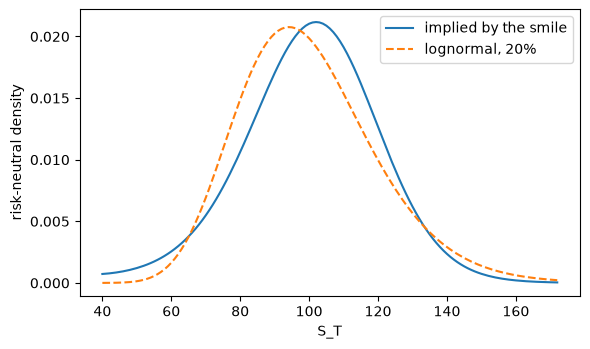

In [4]:
def root(f, a, b):
    fa = f(a)
    for _ in range(100):
        m = 0.5 * (a + b)
        fm = f(m)
        if (fa < 0) == (fm < 0):
            a, fa = m, fm
        else:
            b = m
    return 0.5 * (a + b)


def lognormal_density(K):
    m, s = log(S0) - 0.02, 0.20
    return phi((log(K) - m) / s) / (K * s)


g = lambda K: density(K, smile1)
k_neg = root(g, 3.0, 10.0)
show("density turns negative below (about 6)", k_neg, 6, tol=0.5)
show("density integrated from there upward", 1 - prob_below(k_neg, smile1, dsmile1), 1.06)
diff = lambda K: g(K) - lognormal_density(K)
show("densities cross, left shoulder starts", root(diff, 60, 80), 65, tol=0.5)
show("densities cross, left shoulder ends", root(diff, 85, 100), 97, tol=0.5)

grid = np.linspace(10.0, 400.0, 39001)
vals = np.array([g(k) for k in grid])
mass = float(np.sum(0.5 * (vals[1:] + vals[:-1]) * np.diff(grid)))
note("density integrated from 10 to 400 (over 1: Pr(S_T < 10) < 0)", mass)

try:
    import matplotlib.pyplot as plt
    Ks = np.linspace(40, 172, 133)
    plt.figure(figsize=(6, 3.6))
    plt.plot(Ks, [g(k) for k in Ks], label="implied by the smile")
    plt.plot(Ks, [lognormal_density(k) for k in Ks], "--", label="lognormal, 20%")
    plt.xlabel("S_T")
    plt.ylabel("risk-neutral density")
    plt.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    pass

## 4. 由六个报价得到一个分布：例 19.2

表 10.2 的期权链：六个看涨期权，执行价间隔 2.50 美元，$r = 5\%$，$T = 45/365$。
每个蝶式是一个二阶差分，两端的看涨价差各是一个数字期权；无论报价是多少，三部分
都因裂项相消而合计为 100%。用于比较的对数正态分布以例 11.4 的隐含远期为中心。

In [5]:
T, r, h = 45 / 365, 0.05, 2.50
K = [42.50, 45.00, 47.50, 50.00, 52.50, 55.00]
C = [6.650, 4.425, 2.670, 1.475, 0.710, 0.305]
grow = exp(r * T)

fly = [C[i - 1] - 2 * C[i] + C[i + 1] for i in range(1, 5)]
dens = [grow * b / h**2 for b in fly]
for k, b, gk, pb, pg in zip(K[1:5], fly, dens, (0.4700, 0.5600, 0.4300, 0.3600), (0.0757, 0.0902, 0.0692, 0.0580)):
    show("butterfly at %.2f" % k, b, pb)
    show("density g(K) at %.2f" % k, gk, pg)
print()
bucket = [100 * gk * h for gk in dens]
for k, b, pb in zip(K[1:5], bucket, (18.9, 22.5, 17.3, 14.5)):
    show("bucket around %.2f (%%)" % k, b, pb)
centre = sum(bucket)
show("probability from 43.75 to 53.75 (%)", centre, 73.3)
up_lo = 100 * grow * (C[0] - C[1]) / h
up_hi = 100 * grow * (C[4] - C[5]) / h
show("Pr(S_T > 43.75) (%)", up_lo, 89.6)
show("Pr(S_T > 53.75) (%)", up_hi, 16.3)
show("Pr(S_T < 43.75) (%)", 100 - up_lo, 10.4)
show("the three pieces (an identity) (%)", 100 - up_lo + centre + up_hi, 100.0, tol=1e-9)
print()
F_impl = 47.50 + (2.67 - 2.575) * exp(r * T)   # Example 11.4's implied forward
show("Example 11.4's forward", F_impl, 47.60)


def band(s, lo=43.75, hi=53.75):
    m, sd = log(F_impl) - 0.5 * s * s * T, s * sqrt(T)
    return N((log(hi) - m) / sd) - N((log(lo) - m) / sd)


show("lognormal at 39.7%, same band (%)", 100 * band(0.397), 53.0)
lo, hi = 0.05, 0.60
for _ in range(200):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if band(mid) > centre / 100 else (lo, mid)
show("lognormal volatility that puts 73.3% there (%)", 100 * mid, 25.6)
show("each $0.10 of early-exercise premium, tail points", 100 * grow * 0.10 / h, 4.0)

butterfly at 45.00                                               0.47   book       0.47   ok
density g(K) at 45.00                                        0.075665   book     0.0757   ok
butterfly at 47.50                                               0.56   book       0.56   ok
density g(K) at 47.50                                        0.090154   book     0.0902   ok
butterfly at 50.00                                               0.43   book       0.43   ok
density g(K) at 50.00                                       0.0692254   book     0.0692   ok
butterfly at 52.50                                               0.36   book       0.36   ok
density g(K) at 52.50                                       0.0579562   book      0.058   ok

bucket around 45.00 (%)                                       18.9162   book       18.9   ok
bucket around 47.50 (%)                                       22.5385   book       22.5   ok
bucket around 50.00 (%)                                       17.3064

## 5. 一年期偏斜上的方差期权序列：式 (19.2) 与第 19.3 节

先看 $1/K^2$ 权重：执行价 60 的权重是平值的 2.8 倍，140 的约为一半。然后把式 (19.2)
用在图 19.1 一年期曲线的坐标上，点间线性插值，70 以下与 130 以上保持端点值不变。
平坦微笑的对照在足够宽的区间上必须给出 20.00%；截断到 70–130 后，连平坦微笑也会
少半个点。带偏斜的期权序列比平值的 20% 高出四个多点，这就是第 22.6 节测得的数字。

In [6]:
for k, printed in ((60, 2.8), (140, 0.5)):
    show("1/K^2 weight at %d, relative to 100" % k, (100 / k) ** 2, printed, tol=0.05)

fig_K = np.array([70, 75, 80, 85, 90, 95, 100, 105, 110, 115, 120, 125, 130], float)
fig_v = np.array([35.53, 31.64, 28.38, 25.66, 23.40, 21.53, 20.00, 18.77, 17.79, 17.04, 16.48, 16.10, 15.88])
Nv = np.vectorize(N)


def var_strike(lo, hi, flat=None, steps=40000, S=100.0, T=1.0, r=0.0):
    # equation (19.2) by the midpoint rule; out-of-the-money options on each side of F
    F = S * exp(r * T)
    w = (hi - lo) / steps
    k = lo + (np.arange(steps) + 0.5) * w
    s = np.full_like(k, flat) if flat is not None else np.interp(k, fig_K, fig_v) / 100
    d1 = (np.log(S / k) + (r + 0.5 * s * s) * T) / (s * sqrt(T))
    c = S * Nv(d1) - k * exp(-r * T) * Nv(d1 - s * sqrt(T))
    opt = np.where(k < F, c - S + k * exp(-r * T), c)
    return 100 * sqrt(2 * exp(r * T) / T * np.sum(w * opt / k**2))


show("control: flat 20%, strikes 50-200", var_strike(50, 200, flat=0.20), 20.00)
show("flat 20%, truncated to 70-130", var_strike(70, 130, flat=0.20), 19.56)
show("one-year skew, strikes 50-200", var_strike(50, 200), 24.38)
show("one-year skew, truncated to 70-130", var_strike(70, 130), 21.99)

1/K^2 weight at 60, relative to 100                           2.77778   book        2.8   ok
1/K^2 weight at 140, relative to 100                         0.510204   book        0.5   ok
control: flat 20%, strikes 50-200                             19.9993   book         20   ok
flat 20%, truncated to 70-130                                 19.5552   book      19.56   ok
one-year skew, strikes 50-200                                 24.3786   book      24.38   ok
one-year skew, truncated to 70-130                            21.9877   book      21.99   ok


## 6. 翼部最多能陡升多快：例 19.3

一旦 $d\sigma/dK > e^{-rT}N(d_2)/\mathcal{V}$，看涨价差就会变成负值。下表给出每 5 个
执行价点的这一上限；突破上限的期权链使 115/120 看涨价差的价格为 −0.3878 美元，再用
二分法求出这条链能承受的最大 $\sigma(120)$。

In [7]:
S, T, r = 100.0, 0.5, 0.03
for k, s, pv, pcap in ((110, 0.225, 25.77, 5.34), (115, 0.240, 22.83, 4.45),
                       (120, 0.260, 20.19, 3.86), (125, 0.290, 18.60, 3.49)):
    v = vega(S, k, T, r, s)
    _, d2 = d12(S, k, T, r, s)
    show("vega at %d" % k, v, pv)
    show("maximum steepening per 5 of strike at %d (points)" % k, 5 * exp(-r * T) * N(d2) / v * 100, pcap)
print()
chain = ((100, 0.240, 7.4824), (105, 0.232, 5.0715), (110, 0.228, 3.3237), (115, 0.250, 2.6563), (120, 0.310, 3.0442))
prices = []
for k, s, pc in chain:
    prices.append(bs(S, k, T, r, s))
    show("call at %d, sigma %.1f%%" % (k, 100 * s), prices[-1], pc)
for (k, _, _), a, b, pspread in zip(chain[1:], prices, prices[1:], (2.4109, 1.7478, 0.6673, -0.3878)):
    show("call spread ending at %d" % k, a - b, pspread)
show("implied digital, 115/120", exp(r * T) * (prices[3] - prices[4]) / 5, -0.0787)
s_max = implied_vol(prices[3], S, 120, T, r)
show("largest sigma(120) the chain tolerates (%)", 100 * s_max, 29.27)
show("the quoted 31.0% past it (points)", 31.0 - 100 * s_max, 1.7)

vega at 110                                                   25.7709   book      25.77   ok
maximum steepening per 5 of strike at 110 (points)            5.34202   book       5.34   ok
vega at 115                                                   22.8329   book      22.83   ok
maximum steepening per 5 of strike at 115 (points)            4.44608   book       4.45   ok
vega at 120                                                   20.1851   book      20.19   ok
maximum steepening per 5 of strike at 120 (points)            3.85951   book       3.86   ok
vega at 125                                                   18.6031   book       18.6   ok
maximum steepening per 5 of strike at 125 (points)            3.49172   book       3.49   ok

call at 100, sigma 24.0%                                      7.48236   book     7.4824   ok
call at 105, sigma 23.2%                                      5.07146   book     5.0715   ok
call at 110, sigma 22.8%                                      3.32368

## 7. 预定事件的方差：第 19.6 节

总方差对时间可加。15 个交易日的总方差按 35% 计，其中 14 个普通交易日按 25% 计；
两者相减，剩下的就是事件日的方差。

In [8]:
ev = (0.35**2 * 15 - 0.25**2 * 14) / 252
show("event-day variance", ev, 0.0038)
show("event-day standard deviation (%)", 100 * sqrt(ev), 6.2)
show("ordinary-day standard deviation (%)", 100 * 0.25 / sqrt(252), 1.6)

event-day variance                                         0.00381944   book     0.0038   ok
event-day standard deviation (%)                              6.18017   book        6.2   ok
ordinary-day standard deviation (%)                           1.57485   book        1.6   ok


## 8. 隐含相关性：式 (19.3) 与例 19.4

取 $n$ 个等权成分与单一相关系数，式 (19.3) 化为 $\sigma_I^2 = \sigma^2[1/n + \rho(1 - 1/n)]$，
由此解出 $\rho$。然后按 25% 的已实现相关性为指数定价；与 18% 之差就是离散度交易
赚取的部分。图中画出指数波动率随相关性的变化。

implied correlation (%)                                       34.6939   book       34.7   ok
index volatility at 25% correlation (%)                       15.4434   book       15.4   ok
the gap dispersion collects (points)                          2.55655   book        2.6   ok


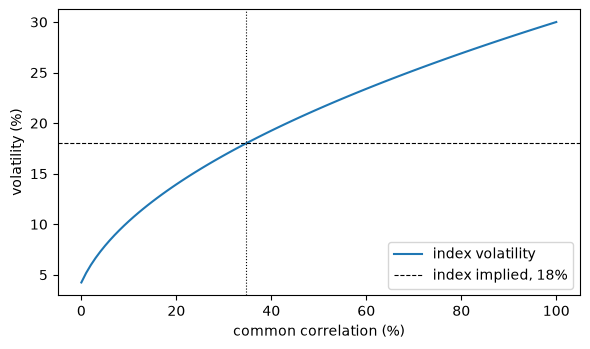

In [9]:
n, s_comp, s_idx = 50, 0.30, 0.18
rho_impl = ((s_idx / s_comp) ** 2 - 1 / n) / (1 - 1 / n)
show("implied correlation (%)", 100 * rho_impl, 34.7)
idx25 = s_comp * sqrt(1 / n + 0.25 * (1 - 1 / n))
show("index volatility at 25% correlation (%)", 100 * idx25, 15.4)
show("the gap dispersion collects (points)", 100 * (s_idx - idx25), 2.6)

try:
    import matplotlib.pyplot as plt
    rhos = np.linspace(0, 1, 101)
    plt.figure(figsize=(6, 3.6))
    plt.plot(100 * rhos, 100 * s_comp * np.sqrt(1 / n + rhos * (1 - 1 / n)), label="index volatility")
    plt.axhline(100 * s_idx, color="k", ls="--", lw=0.8, label="index implied, 18%")
    plt.axvline(100 * rho_impl, color="k", ls=":", lw=0.8)
    plt.xlabel("common correlation (%)")
    plt.ylabel("volatility (%)")
    plt.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    pass

## 9. 粘性 delta 与 delta 修正：式 (19.4)、例 19.5、图 19.4

在粘性 delta 下，微笑是 $K/S$ 的函数，所以现货上涨会给每个执行价一个新的波动率。
式 (19.4) 在布莱克–斯科尔斯 delta 之上加上 vega 乘以 $\partial\sigma/\partial S$；
这里在图 19.1 的一年期偏斜上用中心差分求 $\partial\sigma/\partial S$，取 $r = 0$。
图 19.4 中现货升到 105 之后的粘性 delta 曲线，就是以 105 为现货计算的 $\sigma(K)$。

sigma at 90                                                   0.23397   book      0.234   ok
Black-Scholes delta, 90 put                                 -0.285254   book    -0.2853   ok
correction, 90 put                                           0.125609   book     0.1256   ok
total delta, 90 put                                         -0.159645   book    -0.1596   ok
sigma at 100                                                      0.2   book        0.2   ok
Black-Scholes delta, 100 call                                0.539828   book     0.5398   ok
correction, 100 call                                         0.109162   book     0.1092   ok
total delta, 100 call                                         0.64899   book      0.649   ok
sigma at 110                                                 0.177878   book     0.1779   ok
Black-Scholes delta, 110 call                                0.327481   book     0.3275   ok
correction, 110 call                                        0.0683147 

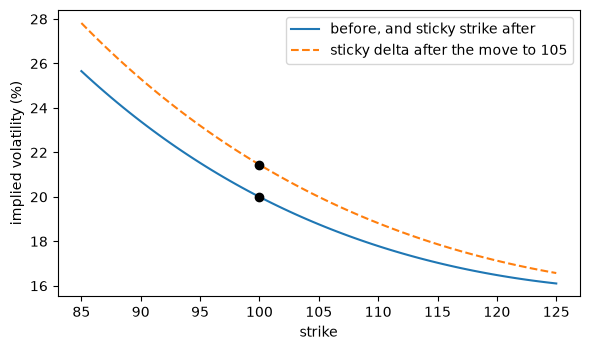

In [10]:
S = 100.0


def dsig_dS(k, spot, eps=1e-4):
    return (skew(k, spot + eps) - skew(k, spot - eps)) / (2 * eps)


rows = ((90, False, 0.2340, -0.2853, 0.1256, -0.1596),
        (100, True, 0.2000, 0.5398, 0.1092, 0.6490),
        (110, True, 0.1779, 0.3275, 0.0683, 0.3958))
for k, is_call, ps, pd, pc, pt in rows:
    s = skew(k, S)
    d1, _ = d12(S, k, 1.0, 0.0, s)
    delta = N(d1) - (0.0 if is_call else 1.0)
    corr = vega(S, k, 1.0, 0.0, s) * dsig_dS(k, S)
    kind = "call" if is_call else "put"
    show("sigma at %d" % k, s, ps)
    show("Black-Scholes delta, %d %s" % (k, kind), delta, pd)
    show("correction, %d %s" % (k, kind), corr, pc)
    show("total delta, %d %s" % (k, kind), delta + corr, pt, tol=1e-4)
atm_corr = vega(S, 100, 1.0, 0.0, 0.20) * dsig_dS(100, S)
show("shares on 100,000 at-the-money options", 100000 * atm_corr, 10920, tol=5)
print()
for k, printed in ((90, 25.31), (95, 23.20), (100, 21.45), (105, 20.00), (110, 18.82), (120, 17.13)):
    show("sticky-delta smile after the move to 105, K = %d (%%)" % k, 100 * skew(k, 105.0), printed)

try:
    import matplotlib.pyplot as plt
    Ks = np.linspace(85, 125, 81)
    plt.figure(figsize=(6, 3.6))
    plt.plot(Ks, [100 * skew(k, 100.0) for k in Ks], label="before, and sticky strike after")
    plt.plot(Ks, [100 * skew(k, 105.0) for k in Ks], "--", label="sticky delta after the move to 105")
    plt.scatter([100, 100], [20.00, 100 * skew(100, 105.0)], color="k", zorder=3)
    plt.xlabel("strike")
    plt.ylabel("implied volatility (%)")
    plt.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    pass

## 10. 标普 500 曲面：表 19.3 与例 19.6

下面从每一行读出偏斜，用该行自己的平值波动率做标准化，并检查第 19.5 节的日历条件：
每一列的总方差都必须随期限上升。然后按例 19.6 为执行价为现货 92% 的九个月看跌期权
定价：在执行价方向线性插值，再沿期限方向按总方差线性插值。若改用平值波动率定价，
同一个看跌期权就丢掉了偏斜。

In [11]:
strikes = [80, 90, 95, 100, 105, 110, 120]
years = [1 / 12, 0.25, 0.5, 1.0, 2.0]
surface = np.array([[30.0, 22.4, 19.6, 17.5, 15.8, 14.9, 15.6],
                    [27.5, 21.9, 19.9, 18.5, 17.1, 16.0, 14.8],
                    [26.0, 21.7, 20.3, 19.3, 18.2, 17.2, 15.6],
                    [25.0, 21.9, 20.8, 20.0, 19.3, 18.5, 17.2],
                    [24.2, 22.0, 21.3, 20.8, 20.2, 19.7, 18.7]])
col = {k: surface[:, i] for i, k in enumerate(strikes)}

slope = (col[90] - col[110]) / 2
for i, printed in ((0, 3.75), (3, 1.70), (4, 1.15)):
    show("skew 90-110 at %.3g years, points per 10%% of spot" % years[i], slope[i], printed)
zslope = [(col[90][i] - col[110][i]) * col[100][i] / 100 * sqrt(t) / (log(1.1) - log(0.9))
          for i, t in enumerate(years)]
show("skew per standard deviation, one month", zslope[0], 1.89)
show("skew per standard deviation, two years", zslope[4], 3.37)
w = (surface / 100) ** 2 * np.array(years)[:, None]
note("total variance rises down every column (1 = yes)", float(np.all(np.diff(w, axis=0) > 0)))
show("total variance, 110 strike, one month", w[0, 5], 0.0019)
show("total variance, 110 strike, two years", w[4, 5], 0.0776)
print()
f = (92 - 90) / (95 - 90)
s6 = col[90][2] + f * (col[95][2] - col[90][2])
s12 = col[90][3] + f * (col[95][3] - col[90][3])
show("six-month volatility at 92 (%)", s6, 21.14)
show("one-year volatility at 92 (%)", s12, 21.46)
w6, w12 = (s6 / 100) ** 2 * 0.5, (s12 / 100) ** 2
w9 = w6 + 0.5 * (w12 - w6)
show("total variance at six months", w6, 0.02234)
show("total variance at one year", w12, 0.04605)
show("total variance at nine months", w9, 0.03420)
sig9 = 100 * sqrt(w9 / 0.75)
show("nine-month volatility at 92 (%)", sig9, 21.35)
show("interpolating the volatilities instead (%)", (s6 + s12) / 2, 21.30)
wa = ((col[100][2] / 100) ** 2 * 0.5 + (col[100][3] / 100) ** 2) / 2
atm9 = 100 * sqrt(wa / 0.75)
show("nine-month at-the-money volatility (%)", atm9, 19.77)
quoted = bs(5000, 4600, 0.75, 0.04, sig9 / 100, q=0.015, call=False)
naive = bs(5000, 4600, 0.75, 0.04, atm9 / 100, q=0.015, call=False)
show("the put off the surface (index points)", quoted, 157.9)
show("the put at the at-the-money volatility", naive, 136.2)
show("the gap (index points)", quoted - naive, 21.7)
show("the gap, % of the correct price", 100 * (quoted - naive) / quoted, 13.8)

skew 90-110 at 0.0833 years, points per 10% of spot              3.75   book       3.75   ok
skew 90-110 at 1 years, points per 10% of spot                    1.7   book        1.7   ok
skew 90-110 at 2 years, points per 10% of spot                   1.15   book       1.15   ok
skew per standard deviation, one month                         1.8881   book       1.89   ok
skew per standard deviation, two years                        3.37149   book       3.37   ok
total variance rises down every column (1 = yes)                    1
total variance, 110 strike, one month                      0.00185008   book     0.0019   ok
total variance, 110 strike, two years                        0.077618   book     0.0776   ok

six-month volatility at 92 (%)                                  21.14   book      21.14   ok
one-year volatility at 92 (%)                                   21.46   book      21.46   ok
total variance at six months                                 0.022345   book    0.02234   ok

## 这个 notebook 说明了什么

* 每个执行价只有一个波动率：平价关系使同一执行价的看涨与看跌期权反解出同一个数。
* 微笑就是一个分布。对执行价的二阶导数是密度，一阶导数是数字期权；股票的波动率偏斜，
  就是用布莱克–斯科尔斯波动率表达的厚左尾与薄右尾。
* 六个报价能给出尾部的概率质量，却给不出尾部的形状；合计为 100% 是恒等式。
* $1/K^2$ 期权序列把偏斜变成高于平值波动率的公允方差互换利率；即使微笑是平坦的，截断
  本身也有代价。
* 翼部的斜率有一个硬上限；一条期权链看上去很平滑，却可能以不到两个波动率点的幅度
  突破它。
* 粘性 delta 会改变每一个对冲：修正项是 vega 乘以微笑随现货的漂移。
* 不交易的期权从曲面上定价，沿期限方向按总方差插值；若用平值波动率定价，就丢掉了偏斜。

上面所有数字都是确定性的，并复现了本章。